---
title: "Multivariable Calculus for Energy and Constraints"
short_title: "M3 Multivariable Calculus"
numbering:
  heading_2: true
  equation: true
---

# Partial Derivatives, Gradients and Constraints

:::{tip} Where this sits in the plan
Math for **work and energy** (gradient, conservative forces, stability) and the start of **Lagrangian mechanics** (partial derivatives, Lagrange multipliers).

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Partial derivatives and the gradient | 14 | 4 | 9 | 3 |
| Taylor series and approximations | 11 | 1 | – | 1 |
| Lagrange multipliers | 14 | 4 | – | 22 |
| Vector calculus (curl test) | 16 | 6 | 9 | 3 |

The curl test and line integrals are covered in full in the Chapter 16 vector calculus notes; this notebook focuses on what they rest on.
:::

Exercises have separate **hint** and **answer** dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Partial Derivatives and the Chain Rule

For $f(x, y)$, the partial derivative $\partial f/\partial x$ is the rate of change with $y$ held fixed. Two facts carry most of the weight in physics.

**The total differential.** A small change in both variables changes $f$ by

$$
df = \frac{\partial f}{\partial x}dx + \frac{\partial f}{\partial y}dy .
$$ (eq-total-diff)

**The chain rule.** If $x$ and $y$ depend on $t$, divide {eq}`eq-total-diff` by $dt$:

$$
\frac{df}{dt} = \frac{\partial f}{\partial x}\dot x + \frac{\partial f}{\partial y}\dot y .
$$

If $f$ also depends on $t$ directly, add $\partial f/\partial t$. This distinction between the **total** derivative $df/dt$ and the **partial** derivative $\partial f/\partial t$ is the one Lagrangian and Hamiltonian mechanics rely on: a Lagrangian $\mathcal{L}(q, \dot q, t)$ has $d\mathcal{L}/dt = \sum_i\big(\partial_{q_i}\mathcal{L}\,\dot q_i + \partial_{\dot q_i}\mathcal{L}\,\ddot q_i\big) + \partial_t\mathcal{L}$.

:::{important} Say what is held fixed
In thermodynamics, and sometimes in mechanics, the same quantity is written as a function of different variable sets, so $\partial f/\partial x$ is ambiguous until you say what is held fixed. The notation $\left(\partial f/\partial x\right)_y$ makes it explicit. Schroeder uses this constantly, and it prevents real mistakes.
:::

### Exact differentials

An expression $P\,dx + Q\,dy$ is **exact** if it equals $df$ for some $f$. Since mixed partials of a smooth $f$ agree, exactness requires

$$
\frac{\partial P}{\partial y} = \frac{\partial Q}{\partial x} ,
$$

and on a simply connected region that condition is also sufficient. This is the same cross-partial test as for conservative forces: a force is conservative exactly when $\vec{F}\cdot d\vec{r}$ is an exact differential, $-dU$. In three dimensions the condition becomes $\nabla\times\vec{F} = \vec{0}$.

### Exercises

1. For $f = x^2y + \sin(xy)$, compute $f_x$, $f_y$ and check that $f_{xy} = f_{yx}$.
2. Is $(2xy + 3)\,dx + (x^2 - 1)\,dy$ exact? If so, find $f$.
3. A particle moves along $x = \cos t$, $y = \sin t$. Find $df/dt$ for $f = x^2 - y^2$ using the chain rule.

:::{dropdown} Hints
1. Differentiate $\sin(xy)$ with the chain rule.
2. Compare $\partial P/\partial y$ with $\partial Q/\partial x$, then integrate $P$ in $x$.
3. $f_x\dot x + f_y\dot y$ with $\dot x = -\sin t$, $\dot y = \cos t$.
:::

:::{dropdown} Answers
1. $f_x = 2xy + y\cos(xy)$, $f_y = x^2 + x\cos(xy)$, and $f_{xy} = f_{yx} = 2x + \cos(xy) - xy\sin(xy)$.
2. Yes ($2x = 2x$). $f = x^2y + 3x - y$.
3. $df/dt = -4\sin t\cos t = -2\sin 2t$, matching $f = \cos 2t$.
:::

## The Gradient and Directional Derivatives

Collect the partials into a vector:

$$
\nabla f = \left\langle f_x, f_y, f_z\right\rangle, \qquad df = \nabla f\cdot d\vec{r} .
$$

The rate of change of $f$ in the direction of a unit vector $\hat{u}$ is the **directional derivative** $D_{\hat{u}}f = \nabla f\cdot\hat{u} = |\nabla f|\cos\theta$. It is largest when $\hat{u}$ points along $\nabla f$, and zero when $\hat{u}$ is tangent to a level surface. So:

- $\nabla f$ points in the direction of fastest increase, with magnitude equal to that rate.
- $\nabla f$ is perpendicular to the level surfaces of $f$.

In other coordinate systems, divide each partial by its scale factor:

$$
\nabla f = \frac{\partial f}{\partial r}\hat{r} + \frac1r\frac{\partial f}{\partial\theta}\hat{\theta} + \frac{1}{r\sin\theta}\frac{\partial f}{\partial\phi}\hat{\phi} \quad\text{(spherical)}.
$$

For a potential energy $U$, the force $\vec{F} = -\nabla U$ points straight downhill, perpendicular to the equipotentials.

## Taylor Series in Several Variables

Near a point $\vec{r}_0$, a smooth function is approximately

$$
f(\vec{r}_0 + \vec{\epsilon}) \approx f(\vec{r}_0) + \nabla f\cdot\vec{\epsilon} + \frac12\,\vec{\epsilon}^{\mathsf T}H\,\vec{\epsilon} ,
\qquad H_{ij} = \frac{\partial^2 f}{\partial x_i\partial x_j} .
$$ (eq-taylor-multi)

The matrix $H$ of second derivatives is the **Hessian**. At a critical point ($\nabla f = \vec{0}$) the linear term vanishes, and the quadratic term decides the shape:

| Hessian eigenvalues | Critical point | For a potential energy |
|---|---|---|
| all positive | minimum | stable equilibrium |
| all negative | maximum | unstable |
| mixed signs | saddle | unstable |

In two dimensions there is a shortcut: with $D = f_{xx}f_{yy} - f_{xy}^2$, the point is a minimum if $D > 0$ and $f_{xx} > 0$, a maximum if $D > 0$ and $f_{xx} < 0$, and a saddle if $D < 0$.

**Why this matters for mechanics.** Near a stable equilibrium, the potential is a quadratic form, so every small motion is a combination of simple harmonic oscillations. That is the whole basis of the small-oscillation and normal-mode chapters, where the Hessian becomes the "stiffness matrix".

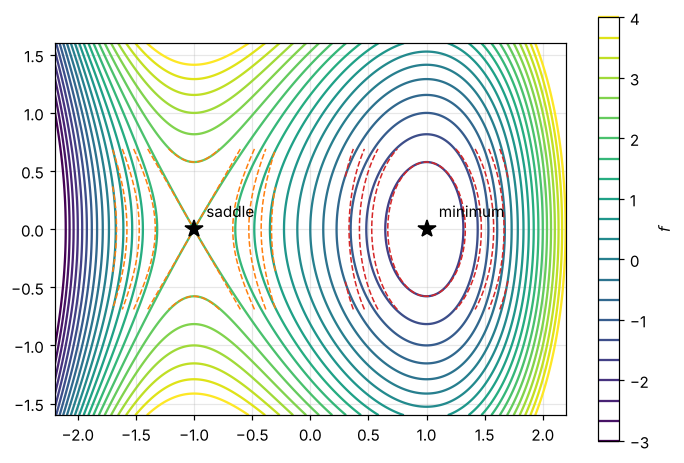

In [2]:
#| label: fig-critical-points
#| caption: The function f = x³ − 3x + y² has a minimum at (1, 0) and a saddle at (−1, 0). The quadratic Taylor approximation (dashed contours) matches the true contours near each point.
x = np.linspace(-2.2, 2.2, 300)
X, Y = np.meshgrid(x, np.linspace(-1.6, 1.6, 300))
F = X**3 - 3 * X + Y**2

fig, ax = plt.subplots(figsize=(7.5, 5))
cs = ax.contour(X, Y, F, levels=np.linspace(-3, 4, 22), cmap="viridis")
for (x0, fxx, c) in [(1, 6, "tab:red"), (-1, -6, "tab:orange")]:
    f0 = x0**3 - 3 * x0
    Q = f0 + 0.5 * fxx * (X - x0)**2 + Y**2
    mask = (np.abs(X - x0) < 0.7) & (np.abs(Y) < 0.7)
    ax.contour(np.where(mask, X, np.nan), np.where(mask, Y, np.nan), np.where(mask, Q, np.nan),
               levels=np.linspace(-3, 4, 22), colors=c, linestyles="--", linewidths=1)
ax.plot([1, -1], [0, 0], "k*", ms=12)
ax.annotate("minimum", (1, 0), textcoords="offset points", xytext=(8, 8))
ax.annotate("saddle", (-1, 0), textcoords="offset points", xytext=(8, 8))
ax.set_aspect("equal"); fig.colorbar(cs, ax=ax, label="$f$"); plt.show()

In [3]:
# Classify critical points with the Hessian
x, y = sp.symbols("x y", real=True)
f = x**3 - 3 * x + y**2
H = sp.hessian(f, (x, y))
for pt in sp.solve([sp.diff(f, x), sp.diff(f, y)], [x, y], dict=True):
    eig = list(H.subs(pt).eigenvals().keys())
    kind = "minimum" if all(e > 0 for e in eig) else "maximum" if all(e < 0 for e in eig) else "saddle"
    display(Math(r"(x, y) = (" + sp.latex(pt[x]) + ", " + sp.latex(pt[y]) + r"):\quad \text{eigenvalues } " + sp.latex(eig) + r"\ \Rightarrow\ \text{" + kind + "}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Find and classify the critical points of $U = x^2 + xy + y^2 - 3x$.
2. Expand $f = e^{x}\cos y$ to second order about the origin.
3. A particle moves in $U(x,y) = \tfrac12k(x^2 + 4y^2)$. Find the small-oscillation frequencies in $x$ and $y$.

:::{dropdown} Hints
1. Solve $\nabla U = 0$, then check $D$.
2. Use {eq}`eq-taylor-multi` or multiply the one-variable series.
3. Each direction is a separate oscillator with spring constant equal to the Hessian entry.
:::

:::{dropdown} Answers
1. $(2, -1)$; $D = 2\cdot2 - 1 = 3 > 0$ and $U_{xx} > 0$, so a minimum.
2. $1 + x + \tfrac12x^2 - \tfrac12y^2$. The origin is a saddle of this approximation.
3. $\omega_x = \sqrt{k/m}$, $\omega_y = 2\sqrt{k/m}$.
:::

## Lagrange Multipliers

To find the extremes of $f(x,y)$ subject to a constraint $g(x,y) = c$, notice that at a constrained extremum the level curve of $f$ must be **tangent** to the constraint curve. Otherwise you could slide along the constraint and increase $f$. Tangent curves have parallel normals, so

$$
\nabla f = \lambda\,\nabla g, \qquad g = c .
$$ (eq-lagrange)

The unknown number $\lambda$ is the **Lagrange multiplier**. In two dimensions this gives three equations for $x$, $y$, $\lambda$. With several constraints, add one multiplier per constraint: $\nabla f = \sum_k \lambda_k\nabla g_k$.

:::{note} The multiplier has a meaning
$\lambda$ measures how fast the optimum value changes as the constraint level $c$ changes: $\lambda = df^*/dc$. In mechanics with constraints, multipliers turn out to be the **constraint forces** (the normal force on a bead, the tension in a pendulum string). In thermodynamics, they become temperature and chemical potential.
:::

::::{prf:example} Largest rectangle in an ellipse
:label: ex-rect-ellipse

Find the largest-area rectangle, with sides parallel to the axes, inscribed in $x^2/a^2 + y^2/b^2 = 1$.

:::{dropdown} Solution
Maximize $f = 4xy$ subject to $g = x^2/a^2 + y^2/b^2 = 1$. Equation {eq}`eq-lagrange` gives

$$
4y = \frac{2\lambda x}{a^2}, \qquad 4x = \frac{2\lambda y}{b^2} .
$$

Dividing them gives $y/x = (b^2/a^2)(x/y)$, so $x^2/a^2 = y^2/b^2 = \tfrac12$. The corner is at $(a/\sqrt2,\ b/\sqrt2)$, and the maximum area is $2ab$.
:::
::::

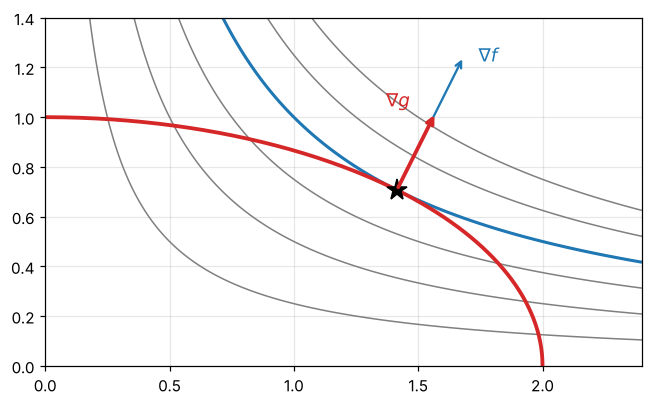

In [4]:
#| label: fig-lagrange
#| caption: Level curves of f = 4xy and the constraint ellipse (a = 2, b = 1). At the optimum (star) the level curve f = 2ab just touches the ellipse, and the two gradients are parallel.
a_, b_ = 2.0, 1.0
x = np.linspace(0.01, 2.4, 300)
X, Y = np.meshgrid(x, np.linspace(0.01, 1.4, 300))
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.contour(X, Y, 4 * X * Y, levels=[1, 2, 3, 4, 5, 6], colors="gray", linewidths=1)
ax.contour(X, Y, 4 * X * Y, levels=[2 * a_ * b_], colors="tab:blue", linewidths=2)
t = np.linspace(0, np.pi / 2, 200)
ax.plot(a_ * np.cos(t), b_ * np.sin(t), "tab:red", lw=2.5)
p = np.array([a_ / np.sqrt(2), b_ / np.sqrt(2)])
gf = np.array([4 * p[1], 4 * p[0]]); gg = np.array([2 * p[0] / a_**2, 2 * p[1] / b_**2])
for v, c, lab, L, off in [(gf, "tab:blue", r"$\nabla f$", 0.6, (0.06, -0.02)),
                          (gg, "tab:red", r"$\nabla g$", 0.35, (-0.2, 0.02))]:
    v = L * v / np.linalg.norm(v)          # the two gradients are parallel, so draw them at different lengths
    ax.annotate("", xy=p + v, xytext=p, arrowprops=dict(arrowstyle="->", color=c, lw=2.5 if c == "tab:red" else 1.5))
    ax.text(p[0] + v[0] + off[0], p[1] + v[1] + off[1], lab, color=c, fontsize=12)
ax.plot(*p, "k*", ms=14)
ax.set_aspect("equal"); ax.set_xlim(0, 2.4); ax.set_ylim(0, 1.4); plt.show()

### Exercises

1. Find the point on the plane $x + 2y + 2z = 9$ closest to the origin.
2. A box with no lid has volume $32$. Minimize its surface area.
3. A bead of mass $m$ hangs at rest on a frictionless circular wire $x^2 + y^2 = R^2$ under gravity. Minimize $U = mgy$ on the circle and interpret $\lambda$.

:::{dropdown} Hints
1. Minimize $x^2 + y^2 + z^2$; the multiplier equations give $\langle x, y, z\rangle\propto\langle1,2,2\rangle$.
2. Minimize $xy + 2xz + 2yz$ subject to $xyz = 32$.
3. $\nabla U = \lambda\nabla(x^2 + y^2)$. Compare $\lambda\nabla g$ with the force the wire must supply.
:::

:::{dropdown} Answers
1. $(1, 2, 2)$, at distance $3$.
2. $x = y = 4$, $z = 2$, area $48$.
3. The minimum is at $x = 0$, $y = -R$ (the bottom), with $\lambda = -mg/(2R)$; the top, $(0, R)$, is the maximum. Equilibrium needs the wire's force to cancel $-\nabla U$, so that force is $\nabla U = \lambda\nabla g = mg\,\hat{y}$: the multiplier times the constraint gradient is the normal force holding the bead up.
:::

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.